# ESTOC 2025

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a map for selected countries.
> Keune, J., F. Di Giuseppe, C. Barnard, E. Damasio da Costa, and F. Wetterhall (2025): ERA5--Drought: Global drought indicators based on ECMWF reanalysis. Sci Data 12, 616 (2025). https://doi.org/10.1038/s41597-025-04896-y.

## Setup and Settings

#### Load libraries

In [1]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import matplotlib.patches as mpatches
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

#### General settings

In [31]:
ref_syyyy = 1991
ref_eyyyy = 2020
indicator = "SPEI"
window    = 1
yyyy      = 2025
mm        = "07"
dataset   = "era5"
stream    = "moda"
distribut = "genlogistic"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#%{yyyy}{mm}01/hr"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
country   = ["Norway","Sweden","Finland"]

In [37]:
dates = pd.date_range(start=f"2025-05-01",end=f"2025-09-01", freq='ME')#[:-8]
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
print(dates)
print(dates.size)

DatetimeIndex(['2025-05-31', '2025-06-30', '2025-07-31', '2025-08-31'], dtype='datetime64[ns]', freq='ME')
4


### Landmask and area

In [38]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']

### Country / Region of interest

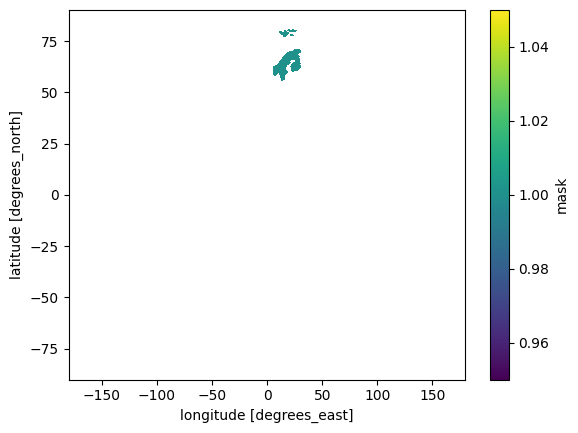

In [39]:
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].plot()
mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[["Norway","Sweden","Finland"]].mask(lmask.lon, lmask.lat)
mask = xr.where(np.isnan(mask), np.nan, 1)
mask.plot()

In [40]:
lon1 = 4  #math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][0])
lon2 = 32 #math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][2])
lat1 = 54 #math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][1])
lat2 = 72 #math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][3])
print(f"Bounding box: lats {lat1} to {lat2}, lons {lon1} to {lon2}")

# surrounding for slice, to avoid cut offs
n=5

Bounding box: lats 54 to 72, lons 4 to 32


## Drought indices

### Read drought index 

In [41]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
print(filelist[:20])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist).sel(lon=slice(lon1-n, lon2+n), lat=slice(lat2+n, lat1-n))
drought_index[window] = xr.where(drought_index[window] == -9999, np.nan, drought_index[window])
print(drought_index[window])

# read barren area mask
vfile = "/home/nejk/code/dryfall_oper/helpers_oper/barren_mask.nc"
bmask = xr.open_dataset(vfile)
drought_index[window] = xr.where( (bmask['barren_mask'][0,:,:] == 1) & (~np.isnan(drought_index[window])) , -9999, drought_index[window])

['/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/20250601/hr/SPEI1_genlogistic_global_era5_moda_ref1991to2020_202506.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/20250701/hr/SPEI1_genlogistic_global_era5_moda_ref1991to2020_202507.nc', '/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs//era5/20250801/hr/SPEI1_genlogistic_global_era5_moda_ref1991to2020_202508.nc']
<xarray.Dataset> Size: 417kB
Dimensions:  (time: 3, lat: 113, lon: 153)
Coordinates:
  * time     (time) datetime64[ns] 24B 2025-06-01T06:00:00 ... 2025-08-01T06:...
  * lat      (lat) float64 904B 77.0 76.75 76.5 76.25 ... 49.75 49.5 49.25 49.0
  * lon      (lon) float64 1kB -1.0 -0.75 -0.5 -0.25 ... 36.25 36.5 36.75 37.0
Data variables:
    SPEI1    (time, lat, lon) float64 415kB dask.array<chunksize=(1, 113, 153), meta=np.ndarray>


### Plot summer maps

/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/usr/local/apps/python3/3.12.11-01/lib/python3.12/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '


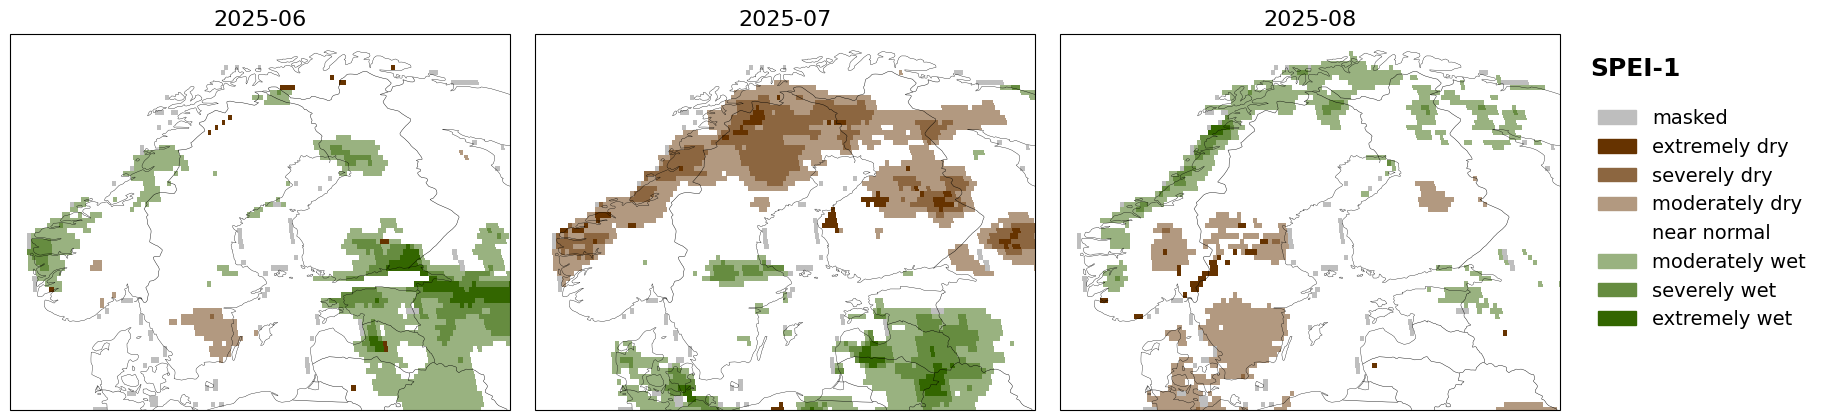

In [42]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]


n = 3
istart = np.where(drought_index[window].time.dt.strftime("%Y-%m") == "2025-06")[0][0]

fig, axes = plt.subplots(
    1, n,
    figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson()}
)

plt.subplots_adjust(wspace=0.05)
fig.suptitle(f"{indicator}-{window}", fontsize=18, y=0.77, x=0.9375, fontweight="bold")

for itime, ax in enumerate(axes):

    toplot = drought_index[window].isel(time=istart + itime)[f"{indicator}{window}"]
    datestr = str(toplot.time.values)[0:7]

    ax.coastlines(color="black", lw=0.25)
    ax.add_feature(cartopy.feature.BORDERS, color="black", lw=0.3)
    ax.set_extent([lon1, lon2, lat1, lat2], crs=ccrs.PlateCarree())


    toplot.plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        x="lon",
        y="lat",
        add_colorbar=False,
        colors=mycollisthex,
        levels=mylevels
    )

    ax.set_title(datestr, fontsize=16)

# add legend
legend_patches = [
    mpatches.Patch(color=mycollisthex[i], label=legnames[i])
    for i in range(len(legnames))
]
fig.legend(
    handles=legend_patches,
    loc="center left",
    bbox_to_anchor=(0.91, 0.5),
    frameon=False,
    fontsize=14
)

plt.savefig(
    f"figures/Fennoscandia_map_{indicator}{window}_JJA_2025_subplots.png",
    dpi=300,
    transparent=True,
    pad_inches=0.1
)

plt.show()